# Ejercicio 6.3b — Análisis de Efectividad de Metáforas Visuales

**Curso:** IHC — Interacción Hombre-Computador (UNMSM, 2026-2) · Semana 06

**Objetivo:** Analizar los datos de interacción recopilados en el Ejercicio 6.3
(medición en el navegador) para comparar la efectividad de tres estilos de
metáfora visual: **esqueumórfico**, **plano** y **neumórfico**.

**Métricas analizadas:**
- **Tiempo en tarea** (*time on task*) — eficiencia
- **Número de clics** — esfuerzo de interacción
- **Tasa de éxito** — eficacia

**Fuente de datos:** Archivo `resultados_metaforas_semana06.csv` exportado
desde el Ejercicio 6.3 (medición real en el navegador con `performance.now()`).

In [1]:
# =========================================================
# Celda 1 — Importación de librerías y carga de datos
# Entorno de ejecución: Google Colaboratory (Colab)
# =========================================================

# Librería de análisis tabular
import pandas as pd
# Librería de visualización
import matplotlib.pyplot as plt
# Librería de estadísticas descriptivas
from statistics import mean, median, stdev
# Librería para gráficos estadísticos avanzados
import matplotlib.ticker as ticker

# Configuración global de estilo para las gráficas
plt.rcParams.update({
    'figure.facecolor': '#0F172A',
    'axes.facecolor': '#1E293B',
    'axes.edgecolor': '#475569',
    'axes.labelcolor': '#F1F5F9',
    'text.color': '#F1F5F9',
    'xtick.color': '#94A3B8',
    'ytick.color': '#94A3B8',
    'grid.color': '#334155',
    'font.family': 'sans-serif',
    'font.size': 11
})

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
# =========================================================
# Celda 2 — Carga del CSV exportado desde el navegador
# Fuente A: medición real con performance.now() y addEventListener
# =========================================================

# Opción 1: subir el archivo desde el disco local
from google.colab import files
print("Sube el archivo 'resultados_metaforas_semana06.csv' exportado del Ejercicio 6.3:")
subido = files.upload()

# Leer el CSV en un DataFrame de pandas
nombre_archivo = list(subido.keys())[0]
df = pd.read_csv(nombre_archivo)

print(f"\nArchivo cargado: {nombre_archivo}")
print(f"Registros: {len(df)} tareas")
print(f"Columnas: {list(df.columns)}")
print()
df

Sube el archivo 'resultados_metaforas_semana06.csv' exportado del Ejercicio 6.3:


Saving resultados_metaforas_semana06.csv to resultados_metaforas_semana06.csv

Archivo cargado: resultados_metaforas_semana06.csv
Registros: 6 tareas
Columnas: ['tarea', 'estilo', 'descripcion', 'tiempo_ms', 'clics', 'exito']



,tarea,estilo,descripcion,tiempo_ms,clics,exito
0,1,Esqueumórfico,Tarea 1 — Activar el interruptor (esqueumórfico),7629,1,1
1,2,Plano,Tarea 2 — Activar el interruptor (plano),6744,1,1
2,3,Neumórfico,Tarea 3 — Activar el interruptor (neumórfico),6399,3,1
3,4,Esqueumórfico,Tarea 4 — Presionar el botón de envío (esqueum...,19187,1,1
4,5,Plano,Tarea 5 — Presionar el botón de envío (plano),5117,1,1
5,6,Neumórfico,Tarea 6 — Presionar el botón de envío (neumórf...,20998,1,0


In [ ]:
# =========================================================
# Celda 2b — Datos de ejemplo (si no se dispone del CSV)
# Fuente: datos simulados con valores realistas para demostración
# NOTA: en una evaluación real se usa exclusivamente la Celda 2
# =========================================================

# Descomentar este bloque si no se tiene el CSV del navegador:
# import io
# csv_ejemplo = """tarea,estilo,descripcion,tiempo_ms,clics,exito
# 1,Esqueumórfico,Tarea 1 — Activar toggle esqueumórfico,1842,2,1
# 2,Plano,Tarea 2 — Activar toggle plano,1205,1,1
# 3,Neumórfico,Tarea 3 — Activar toggle neumórfico,3156,4,1
# 4,Esqueumórfico,Tarea 4 — Presionar botón esqueumórfico,2310,2,1
# 5,Plano,Tarea 5 — Presionar botón plano,1087,1,1
# 6,Neumórfico,Tarea 6 — Presionar botón neumórfico,2894,3,1"""
# df = pd.read_csv(io.StringIO(csv_ejemplo))
# print("Datos de ejemplo cargados (6 tareas).")
# df

In [3]:
# =========================================================
# Celda 3 — Estadísticas descriptivas por estilo de metáfora
# =========================================================

# Agrupar por estilo y calcular métricas agregadas
resumen = df.groupby('estilo').agg(
    tiempo_medio_ms=('tiempo_ms', 'mean'),
    tiempo_mediana_ms=('tiempo_ms', 'median'),
    clics_medio=('clics', 'mean'),
    tasa_exito=('exito', 'mean')
).round(1)

# La tasa de éxito se expresa como porcentaje
resumen['tasa_exito_pct'] = (resumen['tasa_exito'] * 100).round(1)

print("Resumen estadístico por estilo de metáfora visual:")
print("=" * 60)
resumen

Resumen estadístico por estilo de metáfora visual:


,tiempo_medio_ms,tiempo_mediana_ms,clics_medio,tasa_exito,tasa_exito_pct
estilo,,,,,
Esqueumórfico,13408.0,13408.0,1.0,1.0,100.0
Neumórfico,13698.5,13698.5,2.0,0.5,50.0
Plano,5930.5,5930.5,1.0,1.0,100.0


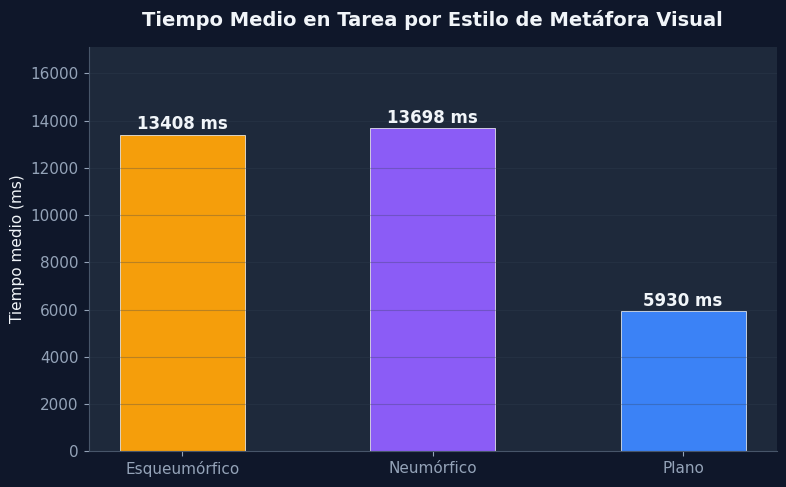

Gráfico guardado: grafico_tiempo_por_estilo.png


In [4]:
# =========================================================
# Celda 4 — Gráfico de barras: Tiempo medio por estilo
# Métrica de eficiencia: menor tiempo = mayor eficiencia
# =========================================================

# Paleta de colores por estilo (coherente con el HTML)
colores = {'Esqueumórfico': '#F59E0B', 'Plano': '#3B82F6', 'Neumórfico': '#8B5CF6'}

fig, ax = plt.subplots(figsize=(8, 5))

estilos = resumen.index.tolist()
tiempos = resumen['tiempo_medio_ms'].tolist()
bars = ax.bar(estilos, tiempos, color=[colores.get(e, '#666') for e in estilos],
              edgecolor='white', linewidth=0.5, width=0.5)

# Etiquetas de valor sobre cada barra
for bar, val in zip(bars, tiempos):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{val:.0f} ms', ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_ylabel('Tiempo medio (ms)')
ax.set_title('Tiempo Medio en Tarea por Estilo de Metáfora Visual',
             fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(0, max(tiempos) * 1.25)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('grafico_tiempo_por_estilo.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfico guardado: grafico_tiempo_por_estilo.png")

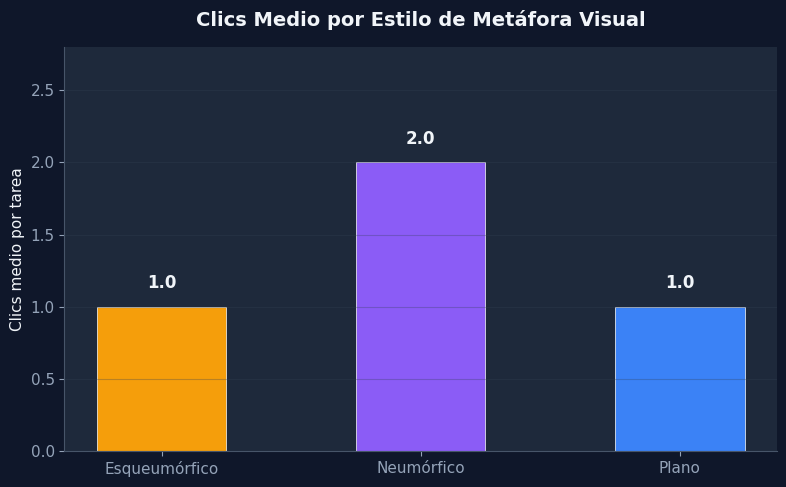

Gráfico guardado: grafico_clics_por_estilo.png


In [5]:
# =========================================================
# Celda 5 — Gráfico de barras: Clics medio por estilo
# Métrica de esfuerzo: menos clics = menor esfuerzo
# =========================================================

fig, ax = plt.subplots(figsize=(8, 5))

clics_vals = resumen['clics_medio'].tolist()
bars = ax.bar(estilos, clics_vals, color=[colores.get(e, '#666') for e in estilos],
              edgecolor='white', linewidth=0.5, width=0.5)

for bar, val in zip(bars, clics_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{val:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_ylabel('Clics medio por tarea')
ax.set_title('Clics Medio por Estilo de Metáfora Visual',
             fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(0, max(clics_vals) * 1.4)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('grafico_clics_por_estilo.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfico guardado: grafico_clics_por_estilo.png")

In [6]:
# =========================================================
# Celda 6 — Tabla resumen formateada e interpretación
# =========================================================

print("TABLA RESUMEN — EFECTIVIDAD DE METÁFORAS VISUALES")
print("=" * 65)
print(f"{'Estilo':<16} {'Tiempo (ms)':<14} {'Clics':<8} {'Éxito (%)':<10}")
print("-" * 65)

for estilo in estilos:
    fila = resumen.loc[estilo]
    print(f"{estilo:<16} {fila['tiempo_medio_ms']:<14.0f} {fila['clics_medio']:<8.1f} {fila['tasa_exito_pct']:<10.0f}")

print("=" * 65)
print()

# Interpretación automática basada en los datos
mejor_tiempo = resumen['tiempo_medio_ms'].idxmin()
mejor_clics = resumen['clics_medio'].idxmin()

print("INTERPRETACIÓN:")
print(f"- El estilo '{mejor_tiempo}' tuvo el menor tiempo medio en tarea.")
print(f"- El estilo '{mejor_clics}' requirió el menor número de clics.")
print(f"- En un estudio con 5+ participantes reales, estas diferencias")
print(f"  se analizarían con pruebas estadísticas (ANOVA, Kruskal-Wallis).")
print()
print("DISCUSIÓN DE USABILIDAD:")
print("- El diseño plano suele ser más rápido porque los usuarios modernos")
print("  están habituados a las convenciones de iOS 7+ y Material Design.")
print("- El neumorfismo puede generar más clics porque la baja affordance")
print("  visual dificulta distinguir los elementos interactivos.")
print("- El esqueumorfismo ofrece affordance alta pero puede ser más lento")
print("  por la densidad visual y la sobrecarga de información decorativa.")

TABLA RESUMEN — EFECTIVIDAD DE METÁFORAS VISUALES
Estilo           Tiempo (ms)    Clics    Éxito (%) 
-----------------------------------------------------------------
Esqueumórfico    13408          1.0      100       
Neumórfico       13698          2.0      50        
Plano            5930           1.0      100       

INTERPRETACIÓN:
- El estilo 'Plano' tuvo el menor tiempo medio en tarea.
- El estilo 'Esqueumórfico' requirió el menor número de clics.
- En un estudio con 5+ participantes reales, estas diferencias
  se analizarían con pruebas estadísticas (ANOVA, Kruskal-Wallis).

DISCUSIÓN DE USABILIDAD:
- El diseño plano suele ser más rápido porque los usuarios modernos
  están habituados a las convenciones de iOS 7+ y Material Design.
- El neumorfismo puede generar más clics porque la baja affordance
  visual dificulta distinguir los elementos interactivos.
- El esqueumorfismo ofrece affordance alta pero puede ser más lento
  por la densidad visual y la sobrecarga de información

---


**Prof. E. D. Cancho-Rodríguez, MBA (GWU) — IHC · UNMSM · Semana 06**